**Name:** Vikrant Haral     
**Division:** E        
**Batch:** E1              
**Roll No.:** TY-319   
**PRN:** 202401040332

**1. Python Implementation:**



**Step 1: Upload the dataset**

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving student_placement_dataset.csv to student_placement_dataset.csv


**Step2: Import libraries and load dataset**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    classification_report
)

# Load dataset
df = pd.read_csv("student_placement_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst Five Rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nStatistical Description:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset Shape: (1200, 18)

First Five Rows:
  Student_ID  Gender      Branch  SSC_Percentage  HSC_Percentage  CGPA  \
0    STU1000    Male  Mechanical            85.2            75.9  7.17   
1    STU1001    Male          IT            85.0            72.7  6.41   
2    STU1002  Female       Civil            79.7            85.1  7.46   
3    STU1003  Female  Mechanical            81.6            67.0  4.51   
4    STU1004    Male    Computer            70.5            78.8  8.19   

   Active_Backlogs  Internships  Projects  Certifications  Aptitude_Score  \
0                2          0.0         3               1            65.0   
1                0          0.0         3               2            69.0   
2                1          1.0         2               0            72.0   
3                1          1.0         0               3            63.0   
4                0          0.0         2               0            62.0   

  Communication_Ski

**Step 3. Analyze the target variable**

Placement Distribution:
Placed
No     673
Yes    527
Name: count, dtype: int64


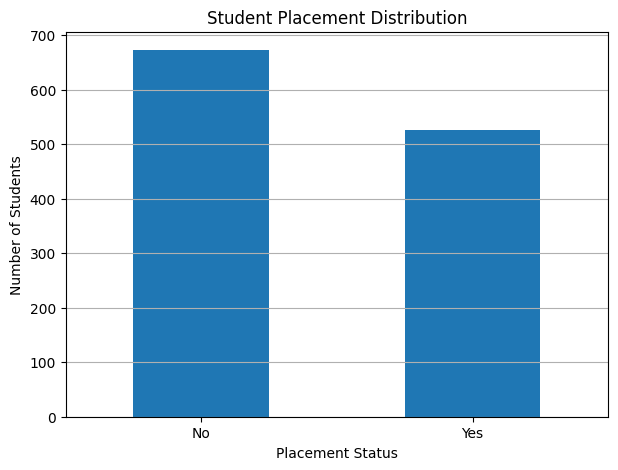

In [ ]:
print("Placement Distribution:")
print(df['Placed'].value_counts())

# Plot placement distribution
df['Placed'].value_counts().plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title("Student Placement Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

**Step 4. Data preprocessing**

In [ ]:
# Remove Student_ID because it is not a predictive feature
X = df.drop(columns=['Student_ID', 'Placed'])

# Convert target variable into numerical values
y = df['Placed'].map({
    'No': 0,
    'Yes': 1
})

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Columns:")
print(numeric_cols)

print("\nCategorical Columns:")
print(categorical_cols)

# Numerical preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Combine preprocessing methods
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nData preprocessing setup completed successfully!")

Numerical Columns:
['SSC_Percentage', 'HSC_Percentage', 'CGPA', 'Active_Backlogs', 'Internships', 'Projects', 'Certifications', 'Aptitude_Score', 'Coding_Hours_Per_Week', 'Family_Income_LPA']

Categorical Columns:
['Gender', 'Branch', 'Communication_Skill', 'City_Tier', 'Hostel_Resident', 'Extracurricular']

Training Data Shape: (960, 16)
Testing Data Shape: (240, 16)

Data preprocessing setup completed successfully!


**2. Model implementation**

**a. Develop classification models:**

In [ ]:
# Define classification models
models = {
    'SVM': SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    ),

    'Decision Tree (CART)': DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        min_samples_leaf=5,
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Naive Bayes': GaussianNB()
}

# Dictionary to store trained models
trained_models = {}

print("Classification Models Created Successfully!")

Classification Models Created Successfully!


**b. Train and evaluate all models:**

In [ ]:
results = []

for name, model in models.items():

    # Create pipeline
    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('classifier', model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Make predictions
    y_pred = pipeline.predict(X_test)

    # Predict probabilities
    y_prob = pipeline.predict_proba(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(y_test, y_pred)

    recall = recall_score(y_test, y_pred)

    f1 = f1_score(y_test, y_pred)

    loss = log_loss(y_test, y_prob)

    # Store results
    results.append({
        'Algorithm': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Log Loss': loss
    })

    trained_models[name] = pipeline

    print("\n", name)
    print("---------------------------")
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))
    print("Log Loss:", round(loss, 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=['Not Placed', 'Placed']
    ))


 SVM
---------------------------
Accuracy: 0.775
Precision: 0.7742
Recall: 0.6857
F1-Score: 0.7273
Log Loss: 0.477

Confusion Matrix:
[[114  21]
 [ 33  72]]

Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.78      0.84      0.81       135
      Placed       0.77      0.69      0.73       105

    accuracy                           0.78       240
   macro avg       0.77      0.77      0.77       240
weighted avg       0.77      0.78      0.77       240


 Decision Tree (CART)
---------------------------
Accuracy: 0.7333
Precision: 0.7253
Recall: 0.6286
F1-Score: 0.6735
Log Loss: 0.5732

Confusion Matrix:
[[110  25]
 [ 39  66]]

Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.74      0.81      0.77       135
      Placed       0.73      0.63      0.67       105

    accuracy                           0.73       240
   macro avg       0.73      0.72      0.72       240
weighted avg      

**c. Comparative analysis:**

In [ ]:
# Convert results into DataFrame
results_df = pd.DataFrame(results)

print("COMPARATIVE ANALYSIS OF CLASSIFICATION MODELS")
print(results_df.round(4))

# Identify best model based on accuracy
best_model = results_df.loc[
    results_df['Accuracy'].idxmax()
]

print("\nBest Performing Model:")
print(best_model)

COMPARATIVE ANALYSIS OF CLASSIFICATION MODELS
              Algorithm  Accuracy  Precision  Recall  F1-Score  Log Loss
0                   SVM    0.7750     0.7742  0.6857    0.7273    0.4770
1  Decision Tree (CART)    0.7333     0.7253  0.6286    0.6735    0.5732
2                   KNN    0.6958     0.6600  0.6286    0.6439    1.5583
3           Naive Bayes    0.7458     0.7037  0.7238    0.7136    0.5423

Best Performing Model:
Algorithm         SVM
Accuracy        0.775
Precision    0.774194
Recall       0.685714
F1-Score     0.727273
Log Loss      0.47697
Name: 0, dtype: object


**d. Visualize model performance:**

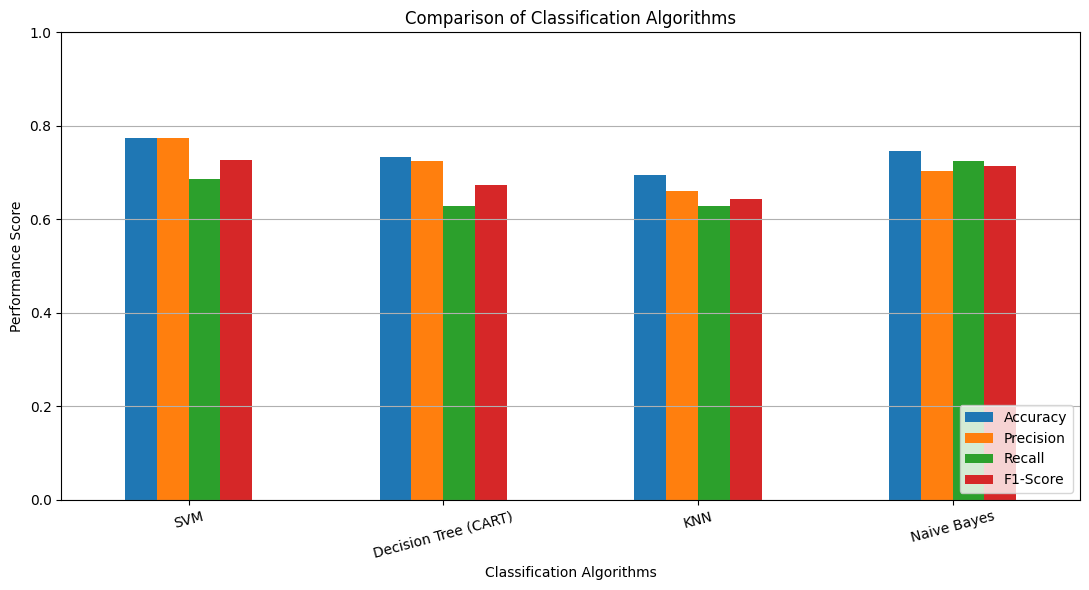

In [ ]:
# Plot comparison of evaluation metrics
metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score'
]

results_df.set_index('Algorithm')[metrics].plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title("Comparison of Classification Algorithms")
plt.xlabel("Classification Algorithms")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

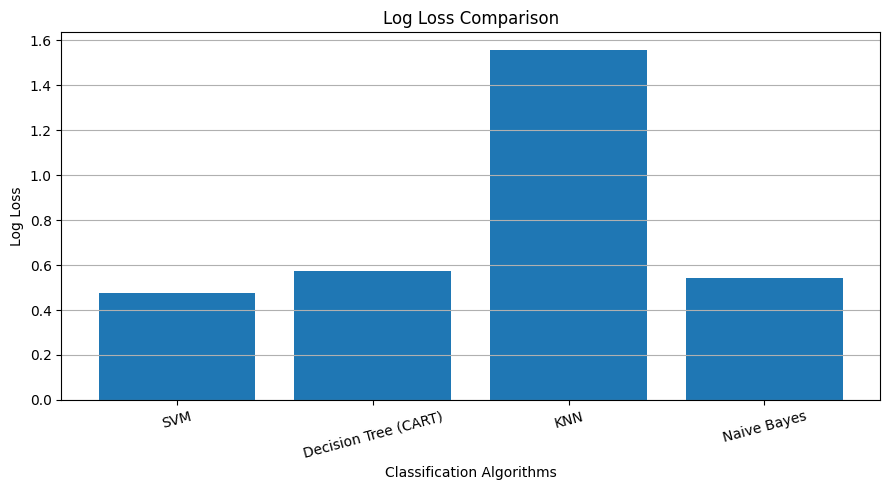

In [ ]:
# Compare Log Loss
plt.figure(figsize=(9, 5))

plt.bar(
    results_df['Algorithm'],
    results_df['Log Loss']
)

plt.title("Log Loss Comparison")
plt.xlabel("Classification Algorithms")
plt.ylabel("Log Loss")

plt.xticks(rotation=15)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**3. Model accuracy comparison:**

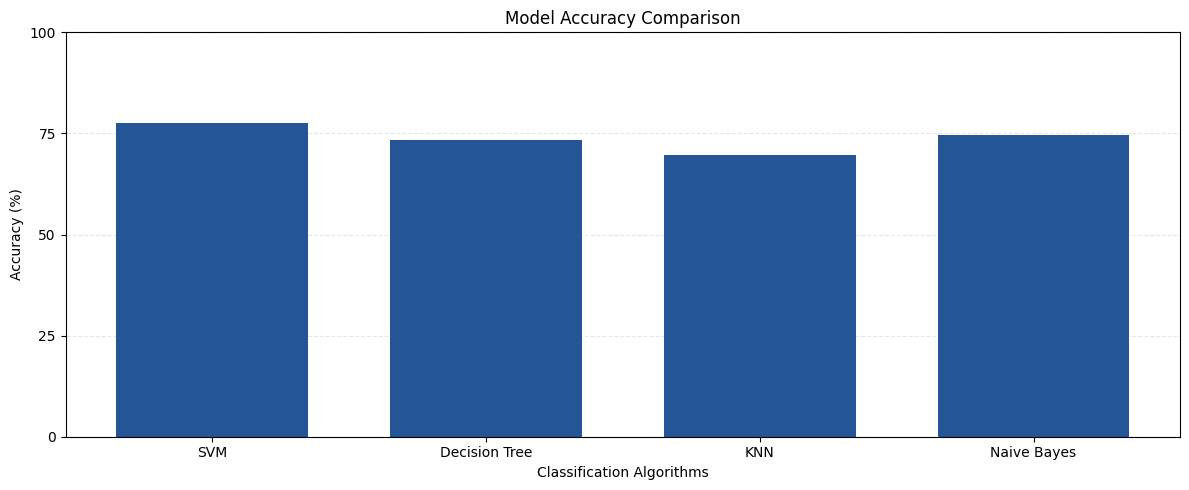

In [ ]:

import matplotlib.pyplot as plt

# Model names
models = ['SVM', 'Decision Tree', 'KNN', 'Naive Bayes']

# Accuracy values (in percentage)
accuracy = [77.50, 73.33, 69.58, 74.58]

# Create bar graph
plt.figure(figsize=(12, 5))

plt.bar(
    models,
    accuracy,
    width=0.7,
    color='#245596'
)

# Add title and labels
plt.title("Model Accuracy Comparison")
plt.xlabel("Classification Algorithms")
plt.ylabel("Accuracy (%)")

# Set Y-axis
plt.ylim(0, 100)
plt.yticks(range(0, 101, 25))

# Add grid
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.gca().set_axisbelow(True)

# Display graph
plt.tight_layout()
plt.show()
